In [1]:
!pip install -q datasets
from datasets import load_dataset
import pandas as pd, json

ds = load_dataset("lmsys/lmsys-arena-human-preference-55k", split="train")
df = ds.to_pandas()
print(df.columns)
df.head()

README.md:   0%|          | 0.00/1.22k [00:00<?, ?B/s]

train.csv: reconstructing file:   0%|          |  0.00B /  184MB            

train.csv: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Index(['id', 'model_a', 'model_b', 'prompt', 'response_a', 'response_b',
       'winner_model_a', 'winner_model_b', 'winner_tie'],
      dtype='object')


,id,model_a,model_b,prompt,response_a,response_b,winner_model_a,winner_model_b,winner_tie
0,30192,gpt-4-1106-preview,gpt-4-0613,"[""Is it morally right to try to have a certain...","[""The question of whether it is morally right ...","[""As an AI, I don't have personal beliefs or o...",1,0,0
1,53567,koala-13b,gpt-4-0613,"[""What is the difference between marriage lice...","[""A marriage license is a legal document that ...","[""A marriage license and a marriage certificat...",0,1,0
2,65089,gpt-3.5-turbo-0613,mistral-medium,"[""explain function calling. how would you call...","[""Function calling is the process of invoking ...","[""Function calling is the process of invoking ...",0,0,1
3,96401,llama-2-13b-chat,mistral-7b-instruct,"[""How can I create a test set for a very rare ...","[""Creating a test set for a very rare category...","[""When building a classifier for a very rare c...",1,0,0
4,198779,koala-13b,gpt-3.5-turbo-0314,"[""What is the best way to travel from Tel-Aviv...","[""The best way to travel from Tel Aviv to Jeru...","[""The best way to travel from Tel-Aviv to Jeru...",0,1,0


In [2]:
rows = []
for _, r in df.iterrows():
    prompts = json.loads(r["prompt"])
    a, b = json.loads(r["response_a"]), json.loads(r["response_b"])
    if len(prompts) != 1:   # keep single-turn only
        continue
    rows.append((r["model_a"], prompts[0], a[0]))
    rows.append((r["model_b"], prompts[0], b[0]))

data = pd.DataFrame(rows, columns=["model", "input", "output"]).dropna()
data["model"].value_counts().head(30)

,count
model,
gpt-4-1106-preview,6415
gpt-3.5-turbo-0613,6115
gpt-4-0613,5303
claude-2.1,4825
gpt-4-0314,3609
claude-instant-1,3597
claude-1,3482
vicuna-33b,3225
mixtral-8x7b-instruct-v0.1,3089


In [3]:
def family(m):
    if m.startswith("gpt-"): return "GPT"
    if m.startswith("claude"): return "Claude"
    if m.startswith("llama-2"): return "Llama"
    if m.startswith(("mixtral", "mistral")): return "Mistral"
    if m.startswith(("gemini", "palm")): return "Google"
    return None

data["family"] = data["model"].apply(family)
data = data.dropna(subset=["family"])

# clean
data = data[data["output"].str.len() > 20]
data = data.drop_duplicates(subset=["output"])

# balance: 4000 per family
N = 4000
data = (data.groupby("family", group_keys=False)
            .apply(lambda g: g.sample(min(len(g), N), random_state=42))
            .reset_index(drop=True))
print(data["family"].value_counts())

# 70/15/15 stratified split
from sklearn.model_selection import train_test_split
train, temp = train_test_split(data, test_size=0.3, stratify=data["family"], random_state=42)
val, test = train_test_split(temp, test_size=0.5, stratify=temp["family"], random_state=42)
print(len(train), len(val), len(test))

data.to_csv("llm_data.csv", index=False)

/tmp/ipykernel_2680/4068063613.py:19: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), N), random_state=42))


family
Claude     4000
GPT        4000
Llama      4000
Mistral    4000
Google     3744
Name: count, dtype: int64
13820 2962 2962


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

def run_baseline(col):
    vec = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), sublinear_tf=True)
    Xtr = vec.fit_transform(train[col])
    Xte = vec.transform(test[col])
    clf = LogisticRegression(max_iter=2000)
    clf.fit(Xtr, train["family"])
    pred = clf.predict(Xte)
    print(f"--- {col} ---")
    print("Accuracy:", round(accuracy_score(test["family"], pred), 3))
    print("Macro F1:", round(f1_score(test["family"], pred, average="macro"), 3))
    print(classification_report(test["family"], pred))

train["both"] = train["input"] + " [SEP] " + train["output"]
test["both"]  = test["input"]  + " [SEP] " + test["output"]

for col in ["output", "input", "both"]:
    run_baseline(col)

--- output ---
Accuracy: 0.598
Macro F1: 0.595
              precision    recall  f1-score   support

      Claude       0.83      0.86      0.84       600
         GPT       0.52      0.56      0.54       600
      Google       0.54      0.61      0.57       562
       Llama       0.60      0.56      0.58       600
     Mistral       0.48      0.39      0.43       600

    accuracy                           0.60      2962
   macro avg       0.59      0.60      0.59      2962
weighted avg       0.60      0.60      0.59      2962

--- input ---
Accuracy: 0.21
Macro F1: 0.21
              precision    recall  f1-score   support

      Claude       0.22      0.24      0.23       600
         GPT       0.20      0.21      0.20       600
      Google       0.23      0.18      0.20       562
       Llama       0.20      0.20      0.20       600
     Mistral       0.21      0.21      0.21       600

    accuracy                           0.21      2962
   macro avg       0.21      0.21      0

In [5]:
for d in (train, val, test):
    d["both"] = d["input"] + " [SEP] " + d["output"]

In [6]:
import re, torch, torch.nn as nn, numpy as np
from collections import Counter
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score

torch.manual_seed(42); np.random.seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
labels = sorted(train["family"].unique())
lab2id = {l: i for i, l in enumerate(labels)}
MAX_LEN = 300

def tokenize(t):
    t = t.replace("\n", " <nl> ")          # keep line breaks as a signal
    return re.findall(r"<nl>|\w+|[^\w\s]", t)  # keep case + punctuation/markdown

def prepare(col):
    counts = Counter(w for t in train[col] for w in tokenize(t))
    vocab = {"<pad>": 0, "<unk>": 1}
    for w, c in counts.most_common(30000):
        if c < 2: break
        vocab[w] = len(vocab)
    def enc(texts):
        X = np.zeros((len(texts), MAX_LEN), dtype=np.int64)
        for i, t in enumerate(texts):
            ids = [vocab.get(w, 1) for w in tokenize(t)][:MAX_LEN]
            X[i, :len(ids)] = ids
        return torch.tensor(X)
    loaders = {}
    for name, df, sh in [("train", train, True), ("val", val, False), ("test", test, False)]:
        y = torch.tensor(df["family"].map(lab2id).values)
        loaders[name] = DataLoader(TensorDataset(enc(df[col].tolist()), y), batch_size=64, shuffle=sh)
    return vocab, loaders

class CNN(nn.Module):
    def __init__(self, V, E=128, F=128, ks=(3, 4, 5), C=5, p=0.5):
        super().__init__()
        self.emb = nn.Embedding(V, E, padding_idx=0)
        self.convs = nn.ModuleList([nn.Conv1d(E, F, k) for k in ks])
        self.drop = nn.Dropout(p)
        self.fc = nn.Linear(F * len(ks), C)
    def forward(self, x):
        e = self.emb(x).transpose(1, 2)
        h = [torch.relu(c(e)).max(dim=2).values for c in self.convs]
        return self.fc(self.drop(torch.cat(h, 1)))

def evaluate(model, loader):
    model.eval(); P, Y = [], []
    with torch.no_grad():
        for X, y in loader:
            P += model(X.to(device)).argmax(1).cpu().tolist(); Y += y.tolist()
    return accuracy_score(Y, P), f1_score(Y, P, average="macro"), P, Y

def train_model(model, loaders, epochs=15, lr=1e-3, patience=3):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    best_f1, best_state, wait, history = 0, None, 0, []
    for ep in range(epochs):
        model.train(); total = 0
        for X, y in loaders["train"]:
            X, y = X.to(device), y.to(device)
            opt.zero_grad()
            loss = loss_fn(model(X), y)
            loss.backward(); opt.step()
            total += loss.item() * len(y)
        tr_loss = total / len(loaders["train"].dataset)
        va_acc, va_f1, _, _ = evaluate(model, loaders["val"])
        history.append((tr_loss, va_acc, va_f1))
        print(f"epoch {ep+1}: loss {tr_loss:.3f} | val acc {va_acc:.3f} | val F1 {va_f1:.3f}")
        if va_f1 > best_f1:
            best_f1, wait = va_f1, 0
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(best_state)
    te_acc, te_f1, P, Y = evaluate(model, loaders["test"])
    print(f"TEST acc {te_acc:.3f} | macro F1 {te_f1:.3f}")
    return model, history, P, Y

vocab, loaders = prepare("output")
cnn, cnn_hist, cnn_P, cnn_Y = train_model(CNN(len(vocab)), loaders)

epoch 1: loss 1.507 | val acc 0.495 | val F1 0.477
epoch 2: loss 1.179 | val acc 0.575 | val F1 0.564
epoch 3: loss 1.058 | val acc 0.572 | val F1 0.565
epoch 4: loss 0.988 | val acc 0.589 | val F1 0.542
epoch 5: loss 0.897 | val acc 0.613 | val F1 0.592
epoch 6: loss 0.819 | val acc 0.613 | val F1 0.616
epoch 7: loss 0.747 | val acc 0.632 | val F1 0.636
epoch 8: loss 0.658 | val acc 0.615 | val F1 0.621
epoch 9: loss 0.569 | val acc 0.626 | val F1 0.626
epoch 10: loss 0.491 | val acc 0.630 | val F1 0.620
TEST acc 0.633 | macro F1 0.637


In [7]:
from torch.nn.utils.rnn import pack_padded_sequence

class LSTM(nn.Module):
    def __init__(self, V, E=128, H=128, C=5, p=0.5):
        super().__init__()
        self.emb = nn.Embedding(V, E, padding_idx=0)
        self.lstm = nn.LSTM(E, H, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(p)
        self.fc = nn.Linear(2 * H, C)
    def forward(self, x):
        lengths = (x != 0).sum(1).clamp(min=1).cpu()
        packed = pack_padded_sequence(self.emb(x), lengths, batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed)
        h = torch.cat([h[-2], h[-1]], 1)   # last forward + backward hidden states
        return self.fc(self.drop(h))

lstm, lstm_hist, lstm_P, lstm_Y = train_model(LSTM(len(vocab)), loaders)

epoch 1: loss 1.298 | val acc 0.470 | val F1 0.466
epoch 2: loss 1.114 | val acc 0.510 | val F1 0.518
epoch 3: loss 0.992 | val acc 0.541 | val F1 0.535
epoch 4: loss 0.856 | val acc 0.543 | val F1 0.538
epoch 5: loss 0.734 | val acc 0.545 | val F1 0.550
epoch 6: loss 0.605 | val acc 0.546 | val F1 0.534
epoch 7: loss 0.471 | val acc 0.557 | val F1 0.561
epoch 8: loss 0.333 | val acc 0.551 | val F1 0.548
epoch 9: loss 0.221 | val acc 0.543 | val F1 0.545
epoch 10: loss 0.149 | val acc 0.548 | val F1 0.547
TEST acc 0.564 | macro F1 0.569


In [8]:
results = {}
results[("CNN", "output")] = evaluate(cnn, loaders["test"])[:2]
results[("LSTM", "output")] = evaluate(lstm, loaders["test"])[:2]

In [9]:
from torch.nn.utils.rnn import pad_packed_sequence

class LSTMPool(LSTM):
    def forward(self, x):
        lengths = (x != 0).sum(1).clamp(min=1).cpu()
        packed = pack_padded_sequence(self.emb(x), lengths, batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
        mask = (x != 0).unsqueeze(-1)
        out = out.masked_fill(~mask, -1e9).max(1).values
        return self.fc(self.drop(out))

lstmp, lstmp_hist, lstmp_P, lstmp_Y = train_model(LSTMPool(len(vocab)), loaders)
results[("LSTM-maxpool", "output")] = evaluate(lstmp, loaders["test"])[:2]

epoch 1: loss 1.449 | val acc 0.501 | val F1 0.487
epoch 2: loss 1.102 | val acc 0.573 | val F1 0.566
epoch 3: loss 0.969 | val acc 0.597 | val F1 0.587
epoch 4: loss 0.850 | val acc 0.623 | val F1 0.625
epoch 5: loss 0.769 | val acc 0.630 | val F1 0.633
epoch 6: loss 0.698 | val acc 0.643 | val F1 0.642
epoch 7: loss 0.609 | val acc 0.646 | val F1 0.649
epoch 8: loss 0.535 | val acc 0.640 | val F1 0.639
epoch 9: loss 0.455 | val acc 0.630 | val F1 0.635
epoch 10: loss 0.416 | val acc 0.641 | val F1 0.643
TEST acc 0.639 | macro F1 0.641


In [10]:
for col in ["input", "both"]:
    v, ld = prepare(col)
    m, _, _, _ = train_model(CNN(len(v)), ld)
    results[("CNN", col)] = evaluate(m, ld["test"])[:2]
    m, _, _, _ = train_model(LSTM(len(v)), ld)
    results[("LSTM", col)] = evaluate(m, ld["test"])[:2]

pd.DataFrame(results, index=["acc", "macro_f1"]).T.round(3)

epoch 1: loss 1.744 | val acc 0.214 | val F1 0.179
epoch 2: loss 1.604 | val acc 0.208 | val F1 0.185
epoch 3: loss 1.559 | val acc 0.217 | val F1 0.197
epoch 4: loss 1.516 | val acc 0.221 | val F1 0.197
epoch 5: loss 1.455 | val acc 0.221 | val F1 0.207
epoch 6: loss 1.395 | val acc 0.220 | val F1 0.206
epoch 7: loss 1.307 | val acc 0.221 | val F1 0.208
epoch 8: loss 1.218 | val acc 0.218 | val F1 0.206
epoch 9: loss 1.114 | val acc 0.222 | val F1 0.214
epoch 10: loss 1.039 | val acc 0.215 | val F1 0.213
epoch 11: loss 0.976 | val acc 0.219 | val F1 0.217
epoch 12: loss 0.888 | val acc 0.223 | val F1 0.221
epoch 13: loss 0.842 | val acc 0.226 | val F1 0.225
epoch 14: loss 0.806 | val acc 0.222 | val F1 0.220
epoch 15: loss 0.751 | val acc 0.215 | val F1 0.210
TEST acc 0.221 | macro F1 0.221
epoch 1: loss 1.618 | val acc 0.214 | val F1 0.204
epoch 2: loss 1.592 | val acc 0.214 | val F1 0.201
epoch 3: loss 1.551 | val acc 0.221 | val F1 0.217
epoch 4: loss 1.470 | val acc 0.221 | val F1

,,acc,macro_f1
CNN,output,0.633,0.637
LSTM,output,0.564,0.569
LSTM-maxpool,output,0.639,0.641
CNN,input,0.221,0.221
LSTM,input,0.202,0.200
CNN,both,0.615,0.614
LSTM,both,0.469,0.473


In [11]:
from sklearn.metrics import classification_report

code_pat = re.compile(r"```|\bdef\s|\bclass\s|\bimport\s|#include|\bSELECT\b|"
                      r"\b(python|javascript|java|c\+\+|sql|code|function|script|compile|bug)\b", re.I)
data["domain"] = data["input"].apply(lambda t: "code" if code_pat.search(t) else "general")
print(data.groupby(["domain", "family"]).size().unstack())

family   Claude   GPT  Google  Llama  Mistral
domain                                       
code        433   418     356    395      379
general    3567  3582    3388   3605     3621


In [15]:
from sklearn.model_selection import GroupShuffleSplit
def split_groups(df):
    g1 = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
    a, b = next(g1.split(df, groups=df["input"]))
    tr, tmp = df.iloc[a], df.iloc[b]
    g2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
    a, b = next(g2.split(tmp, groups=tmp["input"]))
    return tr, tmp.iloc[a], tmp.iloc[b]

def prepare_custom(col, tr, va, tests):
    counts = Counter(w for t in tr[col] for w in tokenize(t))
    vocab = {"<pad>": 0, "<unk>": 1}
    for w, c in counts.most_common(30000):
        if c < 2: break
        vocab[w] = len(vocab)
    def enc(texts):
        X = np.zeros((len(texts), MAX_LEN), dtype=np.int64)
        for i, t in enumerate(texts):
            ids = [vocab.get(w, 1) for w in tokenize(t)][:MAX_LEN]
            X[i, :len(ids)] = ids
        return torch.tensor(X)
    def loader(df, sh):
        y = torch.tensor(df["family"].map(lab2id).values)
        return DataLoader(TensorDataset(enc(df[col].tolist()), y), batch_size=64, shuffle=sh)
    loaders = {"train": loader(tr, True), "val": loader(va, False)}
    for name, df in tests.items():
        loaders[name] = loader(df, False)
    return vocab, loaders

def cross_domain(src, tgt):
    s, t = data[data["domain"] == src], data[data["domain"] == tgt]
    tr, va, te = split_groups(s)
    v, ld = prepare_custom("output", tr, va, {"test": te, "cross": t})
    m, _, _, _ = train_model(CNN(len(v)), ld)
    in_acc, in_f1, _, _ = evaluate(m, ld["test"])
    x_acc, x_f1, P, Y = evaluate(m, ld["cross"])
    print(f"\n{src} -> {src}: acc {in_acc:.3f} F1 {in_f1:.3f}")
    print(f"{src} -> {tgt}: acc {x_acc:.3f} F1 {x_f1:.3f}")
    print(classification_report(Y, P, target_names=labels))
    return in_acc, in_f1, x_acc, x_f1

rq3 = {}
rq3["general -> code"] = cross_domain("general", "code")
rq3["code -> general"] = cross_domain("code", "general")
pd.DataFrame(rq3, index=["in_acc", "in_f1", "cross_acc", "cross_f1"]).T.round(3)

epoch 1: loss 1.538 | val acc 0.536 | val F1 0.543
epoch 2: loss 1.185 | val acc 0.599 | val F1 0.592
epoch 3: loss 1.062 | val acc 0.612 | val F1 0.617
epoch 4: loss 0.999 | val acc 0.614 | val F1 0.619
epoch 5: loss 0.930 | val acc 0.614 | val F1 0.604
epoch 6: loss 0.840 | val acc 0.631 | val F1 0.631
epoch 7: loss 0.765 | val acc 0.628 | val F1 0.637
epoch 8: loss 0.679 | val acc 0.630 | val F1 0.637
epoch 9: loss 0.599 | val acc 0.637 | val F1 0.643
epoch 10: loss 0.518 | val acc 0.628 | val F1 0.620
epoch 11: loss 0.431 | val acc 0.626 | val F1 0.634
epoch 12: loss 0.373 | val acc 0.625 | val F1 0.631
TEST acc 0.629 | macro F1 0.631

general -> general: acc 0.629 F1 0.631
general -> code: acc 0.598 F1 0.595
              precision    recall  f1-score   support

      Claude       0.84      0.82      0.83       433
         GPT       0.56      0.41      0.48       418
      Google       0.51      0.70      0.59       356
       Llama       0.75      0.51      0.61       395
     M

,in_acc,in_f1,cross_acc,cross_f1
general -> code,0.629,0.631,0.598,0.595
code -> general,0.597,0.587,0.456,0.430


In [16]:
def cross_domain_n(src, tgt, n):
    s = data[data["domain"] == src].sample(n, random_state=42)
    t = data[data["domain"] == tgt]
    tr, va, te = split_groups(s)
    v, ld = prepare_custom("output", tr, va, {"test": te, "cross": t})
    m, _, _, _ = train_model(CNN(len(v)), ld)
    return evaluate(m, ld["test"])[:2] + evaluate(m, ld["cross"])[:2]

n_code = (data["domain"] == "code").sum()
rq3["general(small) -> code"] = cross_domain_n("general", "code", n_code)
pd.DataFrame(rq3, index=["in_acc", "in_f1", "cross_acc", "cross_f1"]).T.round(3)

epoch 1: loss 1.870 | val acc 0.360 | val F1 0.257
epoch 2: loss 1.560 | val acc 0.391 | val F1 0.307
epoch 3: loss 1.319 | val acc 0.451 | val F1 0.444
epoch 4: loss 1.157 | val acc 0.465 | val F1 0.431
epoch 5: loss 1.045 | val acc 0.505 | val F1 0.453
epoch 6: loss 0.950 | val acc 0.529 | val F1 0.513
epoch 7: loss 0.868 | val acc 0.498 | val F1 0.471
epoch 8: loss 0.801 | val acc 0.545 | val F1 0.507
epoch 9: loss 0.695 | val acc 0.522 | val F1 0.503
TEST acc 0.456 | macro F1 0.446


,in_acc,in_f1,cross_acc,cross_f1
general -> code,0.629,0.631,0.598,0.595
code -> general,0.597,0.587,0.456,0.430
general(small) -> code,0.456,0.446,0.431,0.402


In [17]:
def feats(t):
    words, lines = t.split(), t.split("\n")
    return dict(
        n_words=len(words),
        n_lines=len(lines),
        ttr=len(set(w.lower() for w in words)) / max(len(words), 1),
        avg_word_len=np.mean([len(w) for w in words]) if words else 0,
        bullets=sum(bool(re.match(r"\s*([-*•]|\d+\.)\s", l)) for l in lines),
        headers=sum(l.strip().startswith("#") for l in lines),
        bold=t.count("**") // 2,
        code_blocks=t.count("```") // 2,
        exclaim=t.count("!"),
        apology=int(bool(re.search(r"\b(sorry|apologi)", t, re.I))),
        as_ai=int(bool(re.search(r"as an ai|language model", t, re.I))),
    )

F = pd.DataFrame([feats(t) for t in data["output"]], index=data.index)
cols = list(F.columns)
F["family"] = data["family"]
F.groupby("family")[cols].mean().round(2)

,n_words,n_lines,ttr,avg_word_len,bullets,headers,bold,code_blocks,exclaim,apology,as_ai
family,,,,,,,,,,,
Claude,162.10,14.66,0.67,5.45,3.79,0.13,0.01,0.14,0.37,0.08,0.02
GPT,192.30,15.11,0.68,5.41,3.37,0.26,0.98,0.17,0.30,0.04,0.05
Google,181.27,16.40,0.63,5.45,5.05,0.20,2.12,0.18,0.15,0.02,0.02
Llama,236.66,15.20,0.58,5.01,3.96,0.17,0.03,0.17,0.61,0.04,0.03
Mistral,204.22,14.04,0.61,5.88,2.84,0.19,0.11,0.17,0.33,0.02,0.02


In [18]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=300, random_state=42)
rf.fit(F.loc[train.index, cols], train["family"])
pred = rf.predict(F.loc[test.index, cols])
print("Style features only acc:", round(accuracy_score(test["family"], pred), 3))
pd.Series(rf.feature_importances_, index=cols).sort_values(ascending=False).round(3)

Style features only acc: 0.463


,0
avg_word_len,0.234
n_words,0.233
ttr,0.224
n_lines,0.123
bullets,0.070
bold,0.043
exclaim,0.030
code_blocks,0.016
apology,0.011
headers,0.009


In [19]:
def strip_format(t):
    t = t.replace("```", " ")
    t = re.sub(r"^\s*([-*•#]+|\d+\.)\s*", "", t, flags=re.M)  # bullets, headers, numbering
    t = t.replace("**", "").replace("\n", " ")
    return t

for d in (train, val, test):
    d["plain"] = d["output"].apply(strip_format)                         # no formatting
    d["first30"] = d["output"].apply(lambda t: " ".join(t.split()[:30]))  # opening only

for col in ["plain", "first30"]:
    v, ld = prepare(col)
    m, _, _, _ = train_model(CNN(len(v)), ld)
    results[("CNN", col)] = evaluate(m, ld["test"])[:2]

pd.DataFrame(results, index=["acc", "macro_f1"]).T.round(3)

epoch 1: loss 1.604 | val acc 0.452 | val F1 0.436
epoch 2: loss 1.295 | val acc 0.484 | val F1 0.441
epoch 3: loss 1.200 | val acc 0.505 | val F1 0.507
epoch 4: loss 1.115 | val acc 0.502 | val F1 0.465
epoch 5: loss 1.052 | val acc 0.544 | val F1 0.524
epoch 6: loss 0.964 | val acc 0.548 | val F1 0.535
epoch 7: loss 0.873 | val acc 0.573 | val F1 0.572
epoch 8: loss 0.769 | val acc 0.573 | val F1 0.576
epoch 9: loss 0.681 | val acc 0.585 | val F1 0.583
epoch 10: loss 0.565 | val acc 0.581 | val F1 0.576
epoch 11: loss 0.473 | val acc 0.556 | val F1 0.560
epoch 12: loss 0.403 | val acc 0.555 | val F1 0.559
TEST acc 0.575 | macro F1 0.573
epoch 1: loss 1.459 | val acc 0.471 | val F1 0.435
epoch 2: loss 1.213 | val acc 0.501 | val F1 0.505
epoch 3: loss 1.132 | val acc 0.503 | val F1 0.504
epoch 4: loss 1.048 | val acc 0.521 | val F1 0.524
epoch 5: loss 0.948 | val acc 0.515 | val F1 0.494
epoch 6: loss 0.838 | val acc 0.521 | val F1 0.520
epoch 7: loss 0.744 | val acc 0.525 | val F1 0.

acc  macro_f1
CNN          output   0.633     0.637
LSTM         output   0.564     0.569
LSTM-maxpool output   0.639     0.641
CNN          input    0.221     0.221
LSTM         input    0.202     0.200
CNN          both     0.615     0.614
LSTM         both     0.469     0.473
CNN          plain    0.575     0.573
             first30  0.547     0.551

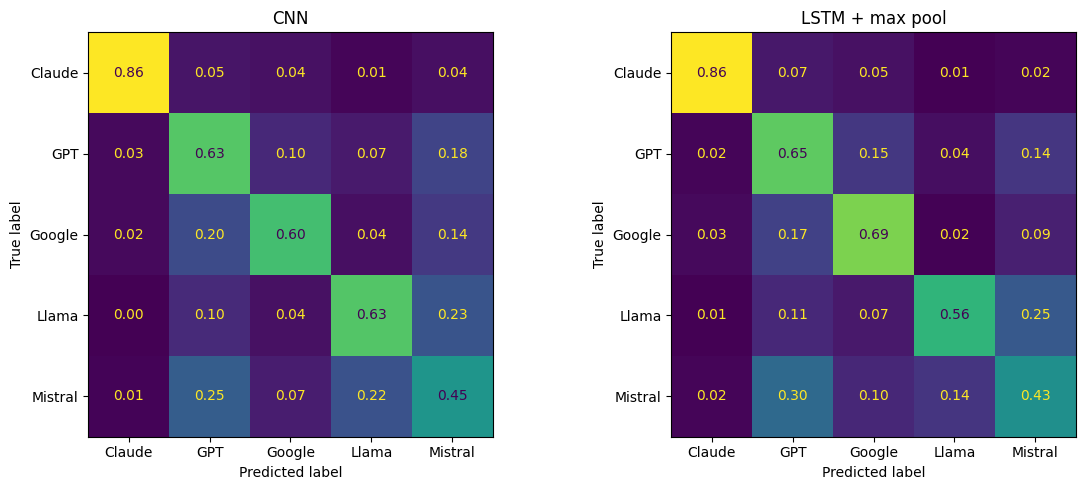

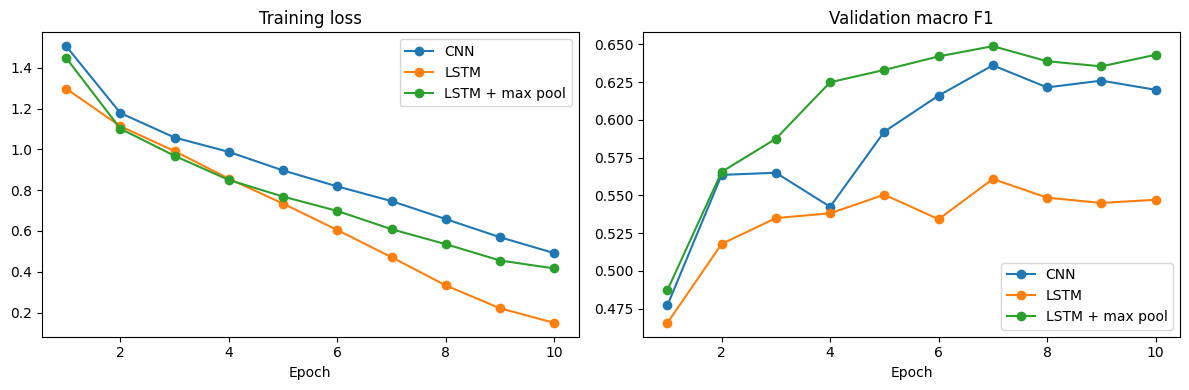

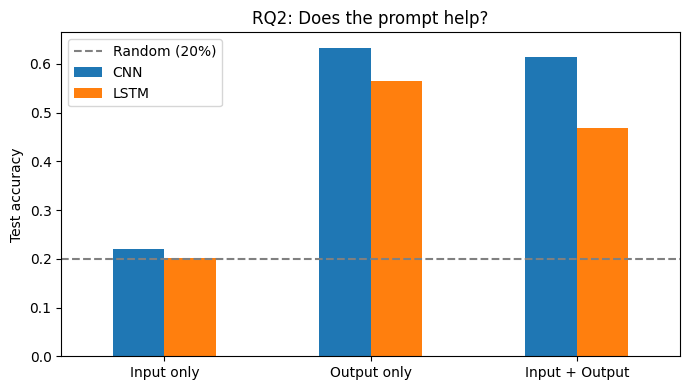

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# 1. Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (P, Y, name) in zip(axes, [(cnn_P, cnn_Y, "CNN"), (lstmp_P, lstmp_Y, "LSTM + max pool")]):
    ConfusionMatrixDisplay.from_predictions(Y, P, display_labels=labels, normalize="true",
                                            values_format=".2f", ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.savefig("confusion.png", dpi=200); plt.show()

# 2. Training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for hist, name in [(cnn_hist, "CNN"), (lstm_hist, "LSTM"), (lstmp_hist, "LSTM + max pool")]:
    h = np.array(hist)
    axes[0].plot(range(1, len(h) + 1), h[:, 0], marker="o", label=name)
    axes[1].plot(range(1, len(h) + 1), h[:, 2], marker="o", label=name)
axes[0].set_title("Training loss"); axes[1].set_title("Validation macro F1")
for ax in axes: ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.savefig("curves.png", dpi=200); plt.show()

# 3. RQ2 bar chart
rq2 = pd.DataFrame({"CNN": [0.221, 0.633, 0.615], "LSTM": [0.202, 0.564, 0.469]},
                   index=["Input only", "Output only", "Input + Output"])
ax = rq2.plot.bar(rot=0, figsize=(7, 4))
ax.axhline(0.2, ls="--", c="gray", label="Random (20%)"); ax.legend()
ax.set_ylabel("Test accuracy"); ax.set_title("RQ2: Does the prompt help?")
plt.tight_layout(); plt.savefig("rq2.png", dpi=200); plt.show()

In [21]:
from google.colab import files
for f in ["confusion.png", "curves.png", "rq2.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>